In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import anndata
import os
import pickle
import warnings
import itertools

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import cut_tree, linkage
from scipy.stats import wilcoxon
from scipy.stats import rankdata
from scipy.stats import rankdata, mannwhitneyu, spearmanr

from sklearn.metrics import silhouette_score as ss
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

import scvelo as scv
import multivelo as mv

warnings.filterwarnings("ignore")

In [2]:
python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

scv.settings.verbosity = 3
scv.settings.presenter_view = True
scv.set_figure_params('scvelo')
scv.settings.figdir = rf"{python_data_dir}\multivelo_comparison"
scv.settings.plot_prefix = ""
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)
np.set_printoptions(suppress=True)

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:27) --> added 
    'velo_s_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing latent time using root_cells_manual, end_cells_manual as prior
    finished (0:00:01) --> added 
    'latent_time', shared time (adata.obs)
computing velocity embedding
    finished (0:00:02) --> added
    'velo_s_norm_umap', embedded velocity vectors (adata.obsm)


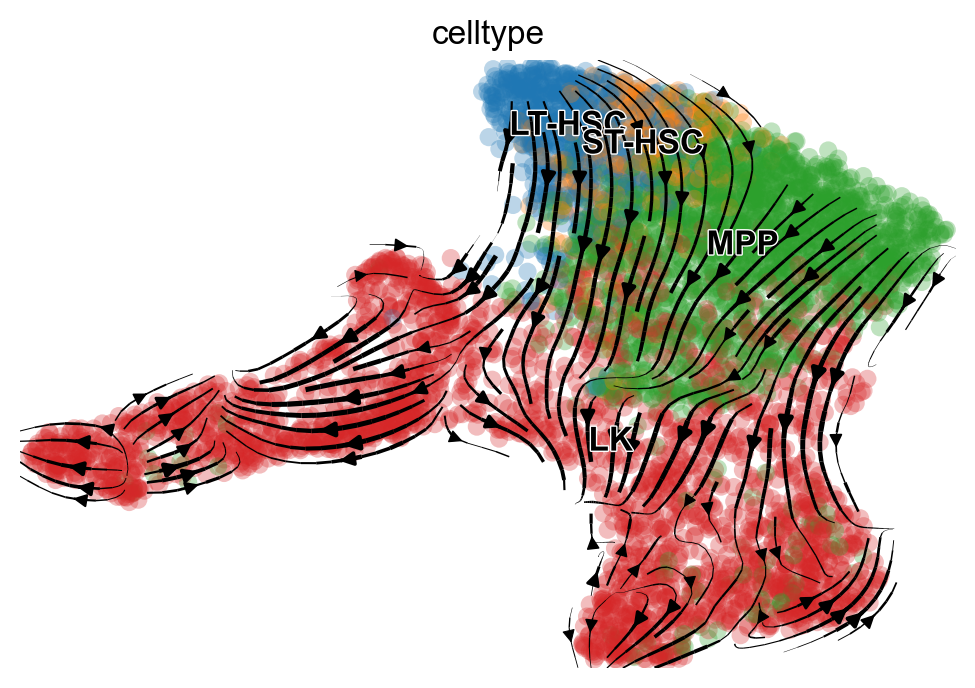

In [ ]:
mv_data = sc.read_h5ad(rf"{python_data_dir}\multivelo_results_v2.h5ad")
mv_data.obs["root_cells_manual"] = mv_data.obs["celltype"] == "LT-HSC"
mv_data.obs["end_cells_manual"] = mv_data.obs["celltype"] == "LK"

# prep MultiVelo data some more
mv.velocity_graph(mv_data, n_jobs=8)
mv.latent_time(mv_data, root_key="root_cells_manual", end_key="end_cells_manual")
mv.velocity_embedding_stream(mv_data, basis='umap', color='celltype')

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:23) --> added 
    'velo_u_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing latent time using root_cells_manual, end_cells_manual as prior
    finished (0:00:01) --> added 
    'latent_time', shared time (adata.obs)
computing velocity embedding
    finished (0:00:01) --> added
    'velo_u_norm_umap', embedded velocity vectors (adata.obsm)


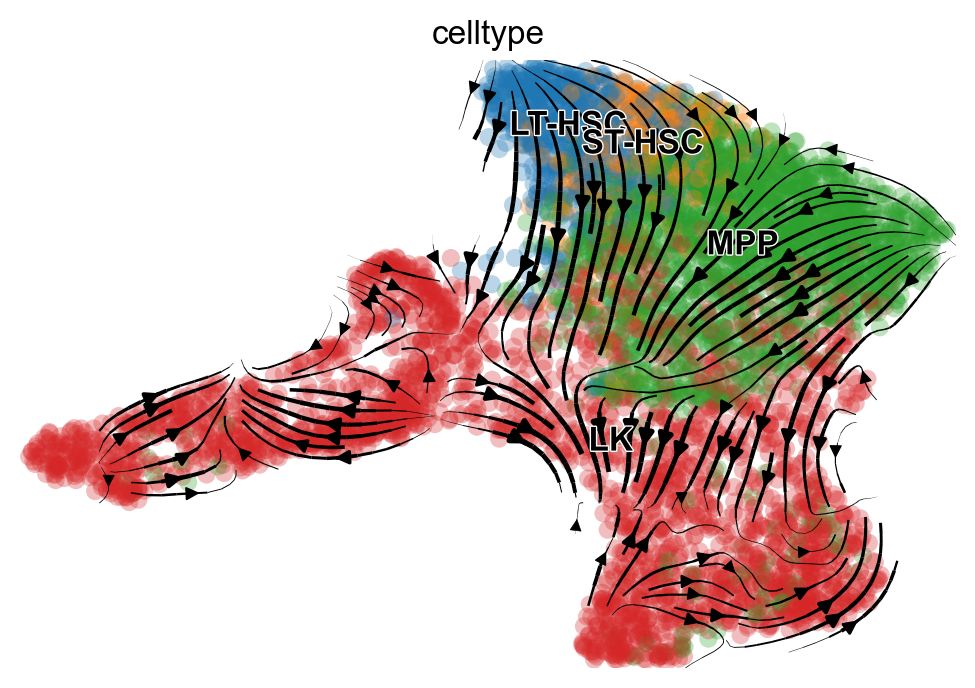

In [7]:
mv.velocity_graph(mv_data, vkey="velo_u", n_jobs=8)
mv.latent_time(mv_data, root_key="root_cells_manual", end_key="end_cells_manual", vkey="velo_u",)
mv.velocity_embedding_stream(mv_data, basis='umap', color='celltype', vkey="velo_u")

computing velocity graph (using 8/8 cores)


  0%|          | 0/5241 [00:00<?, ?cells/s]

    finished (0:00:22) --> added 
    'velo_chrom_norm_graph', sparse matrix with cosine correlations (adata.uns)
computing latent time using root_cells_manual, end_cells_manual as prior
    finished (0:00:01) --> added 
    'latent_time', shared time (adata.obs)
computing velocity embedding
    finished (0:00:01) --> added
    'velo_chrom_norm_umap', embedded velocity vectors (adata.obsm)


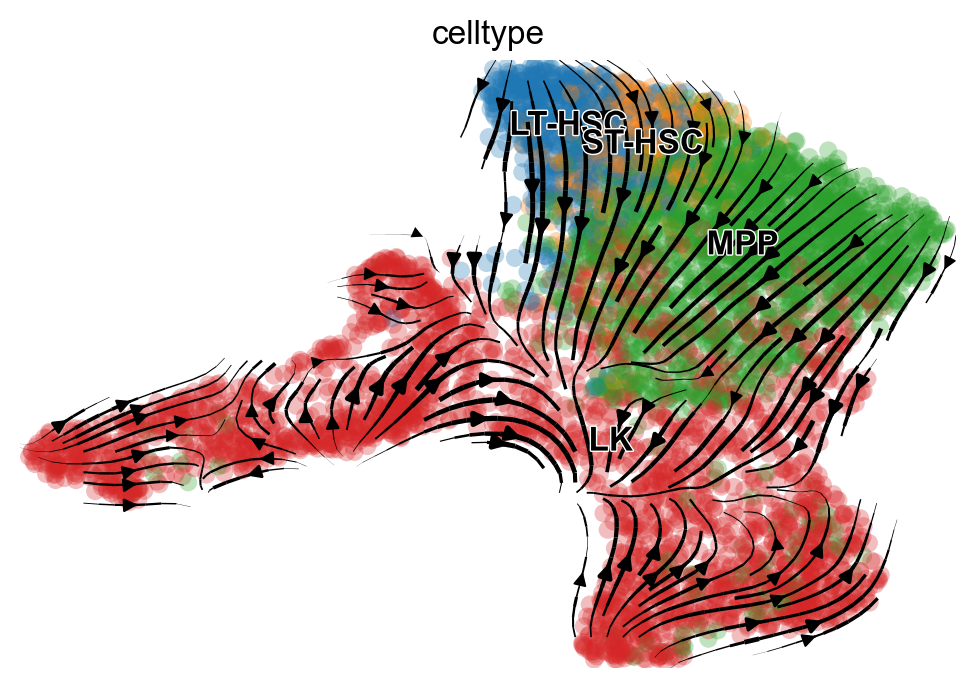

In [32]:
mv.velocity_graph(mv_data, vkey="velo_chrom", n_jobs=8)
mv.latent_time(mv_data, root_key="root_cells_manual", end_key="end_cells_manual", vkey="velo_chrom",)
mv.velocity_embedding_stream(mv_data, basis='umap', color='celltype', vkey="velo_chrom")

In [9]:
mv_data

AnnData object with n_obs × n_vars = 5241 × 310
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Sample', 'TSSEnrichment', 'ReadsInTSS', 'ReadsInPromoter', 'ReadsInBlacklist', 'PromoterRatio', 'PassQC', 'NucleosomeRatio', 'nMultiFrags', 'nMonoFrags', 'nFrags', 'nDiFrags', 'BlacklistRatio', 'percent.mt', 'nCount_SCT', 'nFeature_SCT', 'S.Score', 'G2M.Score', 'Phase', 'SCT_snn_res.0.8', 'seurat_clusters', 'doublets_normal_cluster_based', 'doublets_random', 'doublets_RNA_consensus', 'nCount_SCT_no_regression', 'nFeature_SCT_no_regression', 'tricyclePosition', 'Phase_tricycle', 'tricycle_fine', 'cell_cycle_atac_classification', 'PromoterPercent', 'immunophenotype_predicted', 'predicted.id', 'prediction.score.LT', 'prediction.score.ST', 'prediction.score.MPP', 'prediction.score.LS_K', 'prediction.score.max', 'Identity_for_diff_testing', 'RF_prediction', 'angle_degree', 'immunophenotype_predicted_cleaned', 'HSC.promoters', 'LMPP.promoters', 'myeloid.promoters', 'MEP.promoters', 'HSC.TSS'

In [35]:
mv_data.uns["velo_s_norm_graph"]

<5241x5241 sparse matrix of type '<class 'numpy.float32'>'
	with 1464897 stored elements in Compressed Sparse Row format>

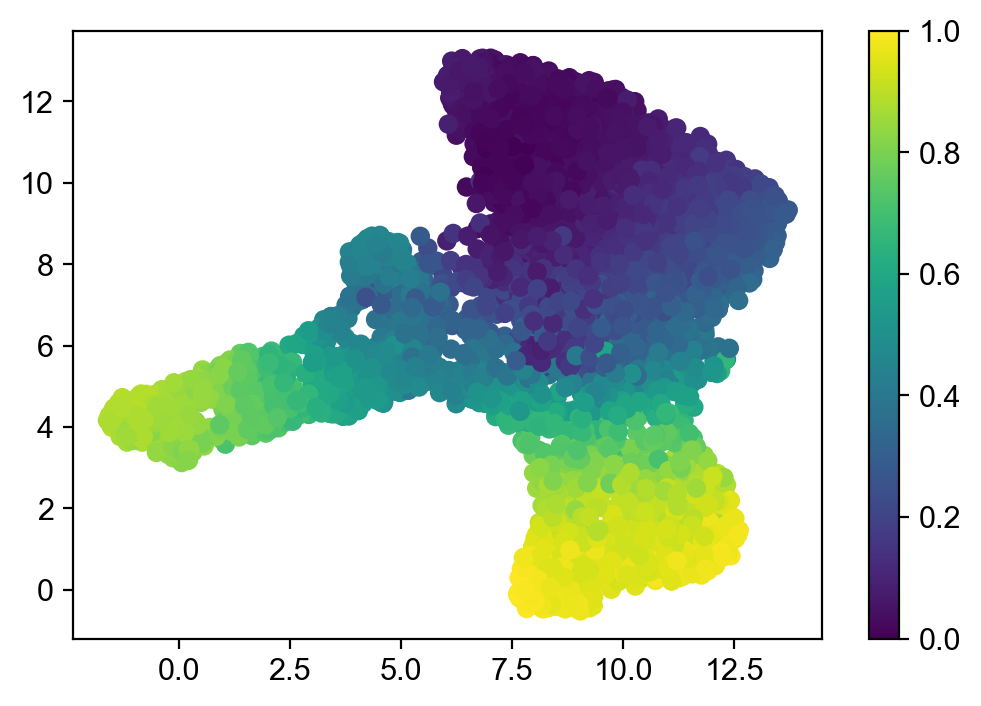

In [5]:
plt.figure()
plt.scatter(mv_data.obsm["X_umap"][:,0], mv_data.obsm["X_umap"][:,1], c=mv_data.obs["latent_time"], cmap="viridis")
plt.colorbar()
plt.show()

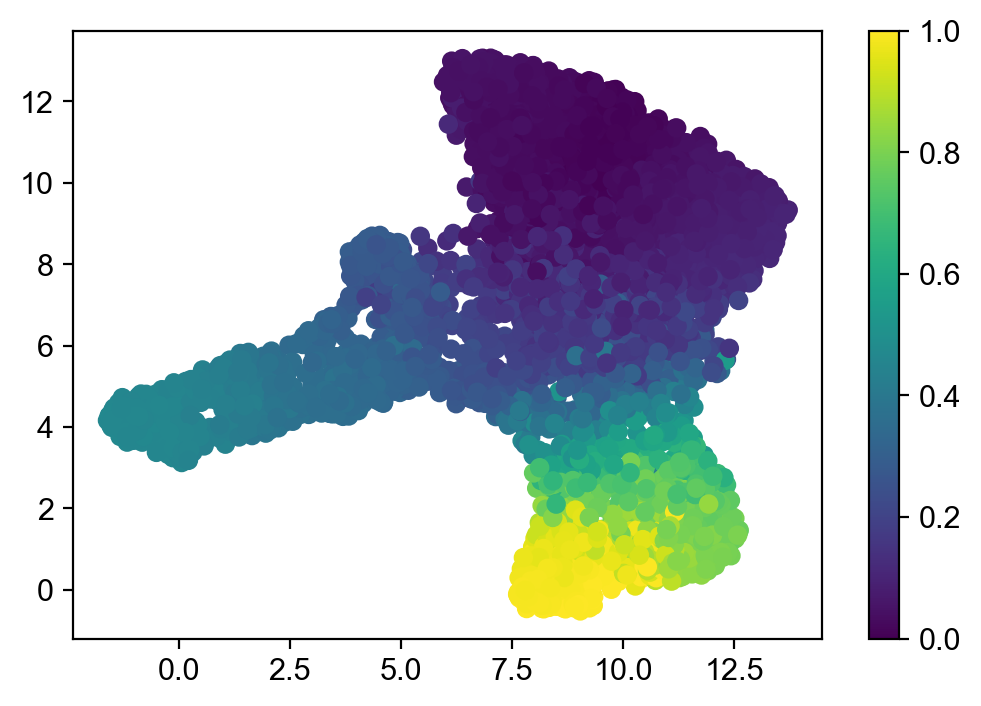

In [6]:
plt.figure()
plt.scatter(mv_data.obsm["X_umap"][:,0], mv_data.obsm["X_umap"][:,1], c=mv_data.obs["velo_s_norm_pseudotime"], cmap="viridis")
plt.colorbar()
plt.show()

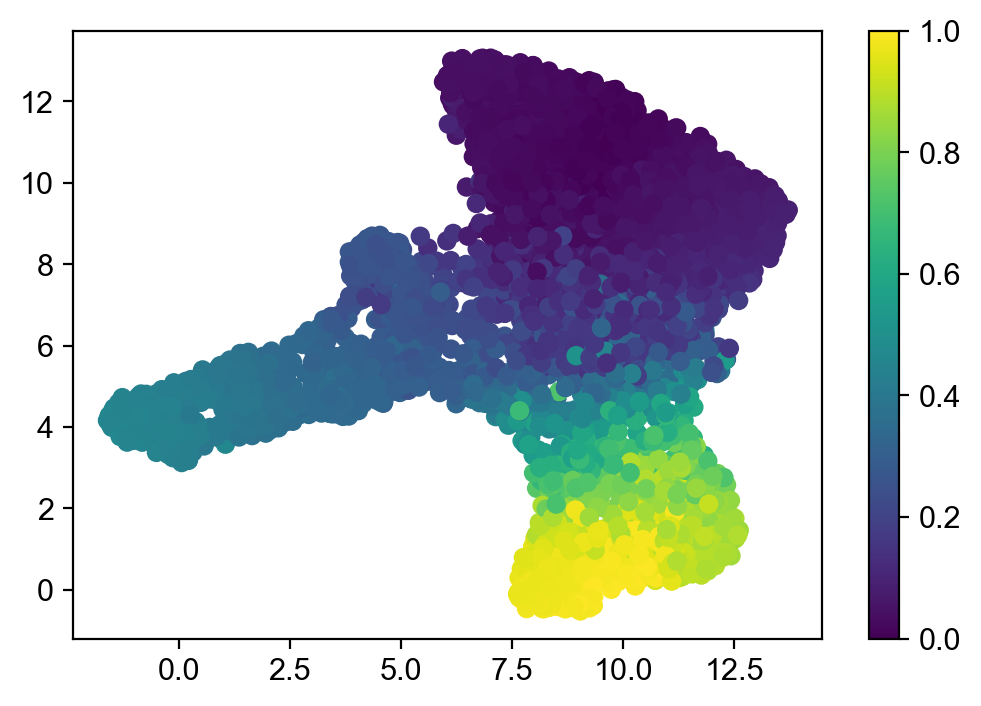

In [8]:
plt.figure()
plt.scatter(mv_data.obsm["X_umap"][:,0], mv_data.obsm["X_umap"][:,1], c=mv_data.obs["velo_u_norm_pseudotime"], cmap="viridis")
plt.colorbar()
plt.show()

In [39]:
mv_data.var_names.values

array(['1700006J14Rik', '2610035D17Rik', '2610307P16Rik', 'Abcb4', 'Actb',
       'Adam22', 'Adamts3', 'Adgrl4', 'Adk', 'Aff1', 'Aff3', 'Agps',
       'Alas1', 'Alcam', 'Angpt1', 'Ap3s1', 'Aplp2', 'Apoe', 'App',
       'Aqp1', 'Arhgap18', 'Arhgap32', 'Arhgap6', 'Arhgef3', 'Arid5b',
       'Arsb', 'Asph', 'Atp8a1', 'Atp8b4', 'Auts2', 'B2m', 'BC035044',
       'Bach2', 'Bcas3', 'Bcl2', 'Blvrb', 'C530008M17Rik', 'Cacnb2',
       'Cadps2', 'Calcrl', 'Calr', 'Camk1d', 'Camk2d', 'Car1', 'Car2',
       'Casp3', 'Ccdc171', 'Ccr2', 'Ccser1', 'Cd27', 'Cd34', 'Cd53',
       'Cd74', 'Cdc14a', 'Cdk8', 'Cers6', 'Ces2g', 'Clec12a', 'Clec2d',
       'Clnk', 'Clybl', 'Cmss1', 'Cobll1', 'Cpa3', 'Crim1', 'Csgalnact1',
       'Ctla2a', 'Ctsg', 'Ctsz', 'Cyth3', 'Dach1', 'Diaph2', 'Diaph3',
       'Dlg2', 'Dnajc6', 'Dst', 'Dstn', 'Dusp2', 'Elane', 'Elovl6',
       'Epsti1', 'Ermap', 'Ern1', 'Esr1', 'Esyt2', 'Exoc6b', 'Ext1',
       'Eya1', 'Eya2', 'F13a1', 'F2r', 'F630028O10Rik', 'Fam117a', 'Fau',
       'F

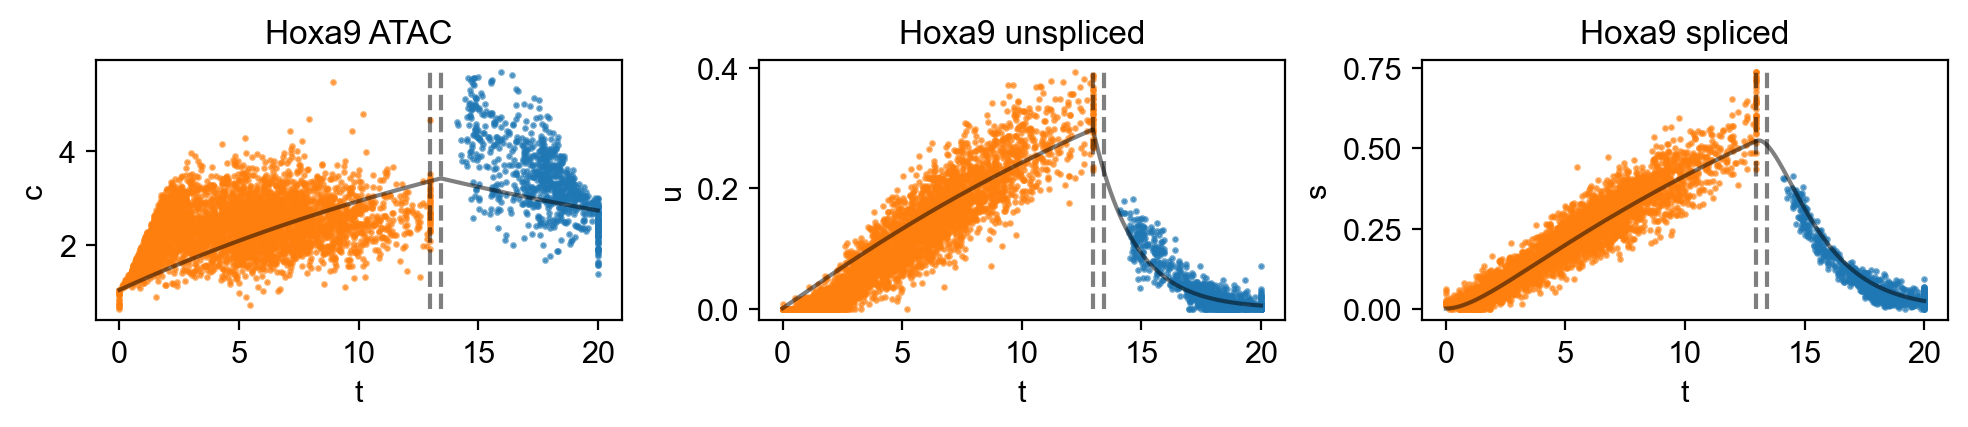

In [40]:
mv.dynamic_plot(mv_data, genes=["Hoxa9"])